<a href="https://colab.research.google.com/github/rahuldevagiri/deep-learning-project/blob/main/notebooks/04_dataset_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell M3.1: everything this notebook needs, in one cell

In [1]:
!pip install -q earthengine-api pyproj
import ee, os, json, hashlib, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pyproj import Transformer
from tqdm.auto import tqdm
from google.colab import drive

PROJECT_ID = "deep-learning-27"                       # replace
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate(force=True); ee.Initialize(project=PROJECT_ID)
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

OUT = "/content/drive/MyDrive/lulc_s1_global"
FROM = [10, 20, 30, 40, 50, 60,  70, 80, 90, 95, 100]
TO   = [ 0,  1,  1,  2,  3,  4, 255,  5,  6,  0,   1]
CLASSES = ["Tree", "Shrub/Grass", "Cropland", "Built-up", "Bare", "Water", "Wetland"]
NC = len(CLASSES)

def label_image():
    return (ee.ImageCollection("ESA/WorldCover/v200").first()
            .remap(FROM, TO, 255).rename("label"))

def split_for(lat, lon):                                   # IDENTICAL to v1 (cell 2.3)
    cell = f"{int(lat // 5)}_{int(lon // 5)}"
    h = int(hashlib.md5(cell.encode()).hexdigest(), 16) % 100
    return "train" if h < 70 else "val" if h < 85 else "test"

def hav_km(lat, lon, LAT, LON):
    """Great-circle distance (km) from one point to arrays of points."""
    lat, lon, LAT, LON = map(np.radians, (lat, lon, LAT, LON))
    a = np.sin((LAT - lat) / 2) ** 2 + np.cos(lat) * np.cos(LAT) * np.sin((LON - lon) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

v1 = pd.read_csv(f"{OUT}/points_meta.csv")
print("v1 points:", len(v1), "| columns:", list(v1.columns)[:12])

Mounted at /content/drive
v1 points: 1740 | columns: ['lat', 'lon', 'cls', 'cont', 'split', 'cls_name', 'pid', 'biome', 'elev', 'slope', 'snow_01', 'snow_02']


M3.2: global candidate pool

In [2]:
eco = ee.FeatureCollection("RESOLVE/ECOREGIONS/2017")
biome = eco.reduceToImage(["BIOME_NUM"], ee.Reducer.first()).toInt()
names = eco.distinct("BIOME_NUM")
biome_names = {int(k): v for k, v in zip(names.aggregate_array("BIOME_NUM").getInfo(),
                                         names.aggregate_array("BIOME_NAME").getInfo())}
print(biome_names)

lab = label_image()
stratum = biome.multiply(10).add(lab).updateMask(lab.neq(255)).rename("stratum").toInt()
strata = [b * 10 + c for b in biome_names for c in range(NC)]
K = 12                                                      # max candidates per stratum per band

def sample_band(w, e, depth=0):
    try:
        fc = stratum.stratifiedSample(numPoints=0, classBand="stratum",
                                      region=ee.Geometry.BBox(w, -56, e, 75), scale=1000,
                                      seed=2026, geometries=True, tileScale=16,
                                      classValues=strata, classPoints=[K] * len(strata))
        return fc.getInfo()["features"]
    except Exception as ex:
        print(f"  [{w},{e}] failed: {str(ex)[:90]}")
        if depth >= 2:
            return []
        mid = (w + e) / 2
        return sample_band(w, mid, depth + 1) + sample_band(mid, e, depth + 1)

cands = []
for w in range(-180, 180, 30):
    feats = sample_band(w, w + 30)
    for f in feats:
        lon, lat = f["geometry"]["coordinates"]; s = int(f["properties"]["stratum"])
        cands.append({"lat": lat, "lon": lon, "biome": s // 10, "cls": s % 10})
    print(f"band {w:>5}..{w + 30:<5}: {len(feats)} candidates")

cand = pd.DataFrame(cands)
cand["biome_name"] = cand.biome.map(biome_names)
cand["cid"] = range(len(cand))
cand.to_csv(f"{OUT}/v2_candidates.csv", index=False)
print("TOTAL candidates:", len(cand))
print(pd.crosstab(cand.biome_name, cand.cls.map(dict(enumerate(CLASSES)))))

{11: 'N/A', 14: 'Mangroves', 5: 'Temperate Conifer Forests', 13: 'Deserts & Xeric Shrublands', 9: 'Flooded Grasslands & Savannas', 10: 'Montane Grasslands & Shrublands', 4: 'Temperate Broadleaf & Mixed Forests', 12: 'Mediterranean Forests, Woodlands & Scrub', 3: 'Tropical & Subtropical Coniferous Forests', 8: 'Temperate Grasslands, Savannas & Shrublands', 2: 'Tropical & Subtropical Dry Broadleaf Forests', 1: 'Tropical & Subtropical Moist Broadleaf Forests', 7: 'Tropical & Subtropical Grasslands, Savannas & Shrublands', 6: 'Boreal Forests/Taiga'}
band  -180..-150 : 446 candidates
band  -150..-120 : 554 candidates
band  -120..-90  : 977 candidates
band   -90..-60  : 1148 candidates
band   -60..-30  : 755 candidates
band   -30..0    : 962 candidates
band     0..30   : 1052 candidates
band    30..60   : 1070 candidates
band    60..90   : 1055 candidates
band    90..120  : 1097 candidates
band   120..150  : 1088 candidates
band   150..180  : 631 candidates
TOTAL candidates: 10835
cls       

M3.3: patch slope for every candidate

In [3]:
dem_col = ee.ImageCollection("COPERNICUS/DEM/GLO30").select("DEM")
dem = dem_col.mosaic().setDefaultProjection(dem_col.first().projection())
slope = ee.Terrain.slope(dem).rename("slope")

res = []
for i in tqdm(range(0, len(cand), 1500)):
    chunk = cand.iloc[i:i + 1500]
    fc = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([r.lon, r.lat]).buffer(1280).bounds(),
                                          {"cid": int(r.cid)}) for r in chunk.itertuples()])
    feats = slope.reduceRegions(collection=fc, reducer=ee.Reducer.mean(), scale=90, tileScale=4).getInfo()["features"]
    res += [{"cid": f["properties"]["cid"], "slope": f["properties"].get("mean")} for f in feats]

cand = cand.drop(columns=["slope"], errors="ignore").merge(pd.DataFrame(res), on="cid", how="left")
cand["mountain"] = cand.slope > 15
cand.to_csv(f"{OUT}/v2_candidates.csv", index=False)
print("candidates with slope:", cand.slope.notna().sum(), "| mountain candidates:", cand.mountain.sum())

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for COPERNICUS/DEM/GLO30! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by COPERNICUS/DEM/GLO30_2024_1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30

  warnings.warn(warning, category=DeprecationWarning)


  0%|          | 0/8 [00:00<?, ?it/s]

candidates with slope: 10824 | mountain candidates: 1199


M3.4: selection rules

In [4]:
from sklearn.neighbors import BallTree
rng = np.random.default_rng(2026)
cand["key"] = rng.random(len(cand)) * np.where(cand.mountain, 0.33, 1.0)   # mountains first (3x priority)

MIN_KM, BUFFER_KM = 10, 25
LAT = np.empty(len(v1) + len(cand)); LON = np.empty_like(LAT)
n = len(v1); LAT[:n], LON[:n] = v1.lat.values, v1.lon.values
cur = v1.biome.dropna().astype(int).value_counts()
tundra_ids = [b for b, nm in biome_names.items() if nm.lower().startswith("tundra")]

picked, report = [], []
for b, bname in biome_names.items():
    quota = max(0, 200 - int(cur.get(b, 0))) + 60
    if b in tundra_ids:
        quota = int(quota * 1.3)
    per_cls = int(np.ceil(quota / NC)); got = 0
    for c in range(NC):
        pool = cand[(cand.biome == b) & (cand.cls == c)].sort_values("key"); k = 0
        for r in pool.itertuples():
            if k >= per_cls:
                break
            if n > 0 and hav_km(r.lat, r.lon, LAT[:n], LON[:n]).min() < MIN_KM:
                continue
            LAT[n], LON[n] = r.lat, r.lon; n += 1; k += 1
            picked.append(r.cid)
        got += k
    report.append({"biome": bname, "v1": int(cur.get(b, 0)), "quota": quota, "selected": got})

sel = cand[cand.cid.isin(picked)].copy()
sel["split"] = [split_for(a, o) for a, o in zip(sel.lat, sel.lon)]

# Cross-split buffer: drop v2 points with a different-split neighbour (v1 or v2) within 25 km
allp = pd.concat([v1[["lat", "lon", "split"]].assign(src="v1"),
                  sel[["lat", "lon", "split"]].assign(src="v2")], ignore_index=True)
tree = BallTree(np.radians(allp[["lat", "lon"]].values), metric="haversine")
nbrs = tree.query_radius(np.radians(allp[["lat", "lon"]].values), r=BUFFER_KM / 6371.0)
sp = allp.split.values
bad = np.array([allp.src.iat[i] == "v2" and any(sp[j] != sp[i] for j in nb) for i, nb in enumerate(nbrs)])
sel = sel[~bad[len(v1):]].copy()
print("dropped by 25 km cross-split buffer:", int(bad.sum()))

sel["pid"] = np.arange(1740, 1740 + len(sel))              # continues after v1 (p00000-p01739)
sel = sel.reset_index(drop=True)
sel.to_json(f"{OUT}/points_v2.json", orient="records")

print(pd.DataFrame(report).to_string(index=False))
print("\nv2 points:", len(sel), "| mountain:", int(sel.mountain.sum()))
combo = pd.concat([v1[["biome_name", "split"]], sel[["biome_name", "split"]]])
print("\n=== v1 + v2: biome x split ===\n", pd.crosstab(combo.biome_name, combo.split, margins=True))

dropped by 25 km cross-split buffer: 16
                                                   biome  v1  quota  selected
                                                     N/A  30    230       217
                                               Mangroves   9    251       252
                               Temperate Conifer Forests  45    215       217
                              Deserts & Xeric Shrublands 206     60        63
                           Flooded Grasslands & Savannas  54    206       210
                         Montane Grasslands & Shrublands  24    236       238
                     Temperate Broadleaf & Mixed Forests 312     60        63
                Mediterranean Forests, Woodlands & Scrub 121    139       140
               Tropical & Subtropical Coniferous Forests   3    257       209
             Temperate Grasslands, Savannas & Shrublands 169     91        91
            Tropical & Subtropical Dry Broadleaf Forests  38    222       224
          Tropical & Sub

Cell M3.4b: map

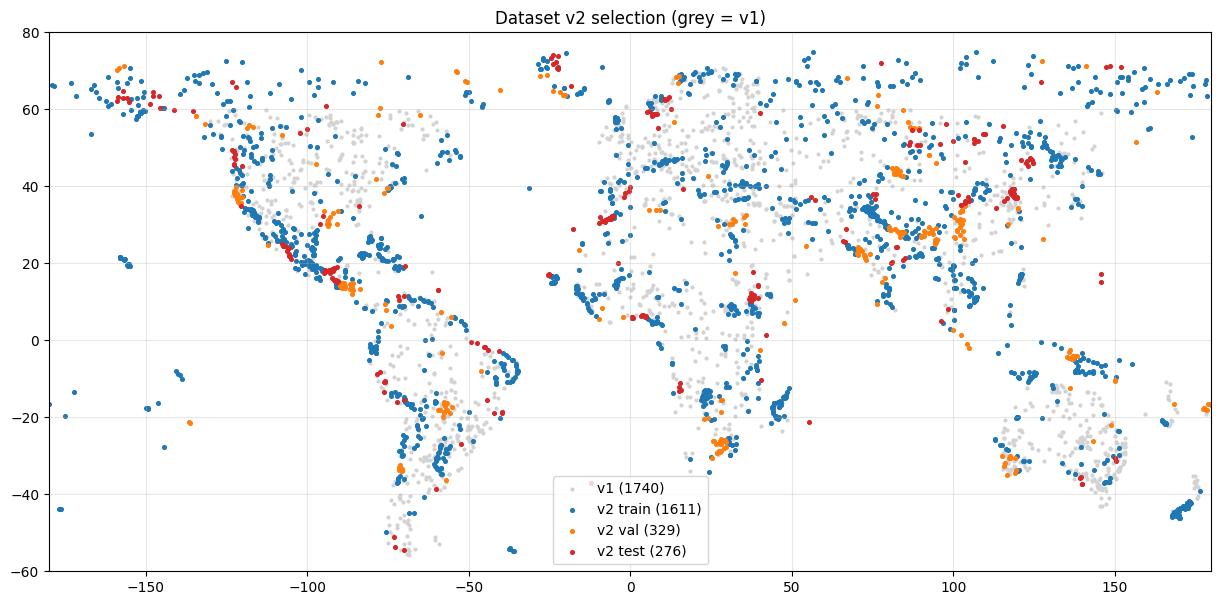

In [5]:
plt.figure(figsize=(15, 7))
plt.scatter(v1.lon, v1.lat, s=4, c="lightgray", label=f"v1 ({len(v1)})")
for s_, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:red")]:
    d = sel[sel.split == s_]; plt.scatter(d.lon, d.lat, s=7, c=c, label=f"v2 {s_} ({len(d)})")
plt.xlim(-180, 180); plt.ylim(-60, 80); plt.grid(alpha=.3); plt.legend()
plt.title("Dataset v2 selection (grey = v1)"); plt.show()

Cell M3.4c

In [6]:
# 1. Show all (number, name) pairs to confirm what number 11 contains
pairs = eco.distinct(["BIOME_NUM", "BIOME_NAME"])
pair_list = sorted(zip(pairs.aggregate_array("BIOME_NUM").getInfo(), pairs.aggregate_array("BIOME_NAME").getInfo()))
print(pair_list)

# 2. Clean names: prefer the real biome name over "N/A" for each number
clean = {}
for num, name in pair_list:
    num = int(num)
    if name != "N/A" or num not in clean:
        clean[num] = name
print("biome 11 ->", clean.get(11))

# 3. Re-label v1 and v2 from the biome NUMBER (never from the stored text)
v1 = pd.read_csv(f"{OUT}/points_meta.csv", keep_default_na=False, na_values=[""])
v1["biome_name"] = v1.biome.map(clean).fillna("Unassigned (coast/water)")
v1.to_csv(f"{OUT}/points_meta.csv", index=False)
sel["biome_name"] = sel.biome.map(clean)
sel.to_json(f"{OUT}/points_v2.json", orient="records")

combo = pd.concat([v1[["biome_name", "split"]], sel[["biome_name", "split"]]])
print(pd.crosstab(combo.biome_name, combo.split, margins=True))

[(1, 'Tropical & Subtropical Moist Broadleaf Forests'), (2, 'Tropical & Subtropical Dry Broadleaf Forests'), (3, 'Tropical & Subtropical Coniferous Forests'), (4, 'Temperate Broadleaf & Mixed Forests'), (5, 'Temperate Conifer Forests'), (6, 'Boreal Forests/Taiga'), (7, 'Tropical & Subtropical Grasslands, Savannas & Shrublands'), (8, 'Temperate Grasslands, Savannas & Shrublands'), (9, 'Flooded Grasslands & Savannas'), (10, 'Montane Grasslands & Shrublands'), (11, 'N/A'), (11, 'Tundra'), (12, 'Mediterranean Forests, Woodlands & Scrub'), (13, 'Deserts & Xeric Shrublands'), (14, 'Mangroves')]
biome 11 -> Tundra
split                                               test  train  val   All
biome_name                                                                
Boreal Forests/Taiga                                  40    185   39   264
Deserts & Xeric Shrublands                            19    222   28   269
Flooded Grasslands & Savannas                         34    178   46   258
Mangroves 

Cell M3.5: run after M3.4c

In [7]:
import zipfile, shutil
from concurrent.futures import ThreadPoolExecutor
YEAR_START, T, RES, NODATA = "2021-01-01", 256, 10, -32768
LOCAL, PARTS = "/content/v2_tmp", f"{OUT}/v2_parts"
os.makedirs(PARTS, exist_ok=True)

def s1_collection(region, start, end):                     # IDENTICAL to v1 (cell 3.1)
    def mask_edges(img):
        a = img.select("angle")
        return img.updateMask(a.gt(30.6).And(a.lt(45.2)))
    return (ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(region).filterDate(start, end)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
            .map(mask_edges).select(["VV", "VH"]))

def monthly_composite(region, start, i):
    s = ee.Date(start).advance(i, "month")
    col = s1_collection(region, s, s.advance(1, "month"))
    empty = ee.Image.constant([0, 0]).rename(["VV", "VH"]).updateMask(0)
    img = ee.Image(ee.Algorithms.If(col.size().gt(0), col.median(), empty))
    return img.multiply(100).round().unmask(NODATA).toInt16().rename([f"VV_{i:02d}", f"VH_{i:02d}"])

def utm_epsg(lat, lon):
    z = int((lon + 180) / 6) + 1
    return f"EPSG:{32600 + z if lat >= 0 else 32700 + z}"

def fetch_local(p, retries=3):
    path = f"{LOCAL}/patches/{p['split']}/p{int(p['pid']):05d}.npz"
    crs = utm_epsg(p["lat"], p["lon"])
    x, y = Transformer.from_crs("EPSG:4326", crs, always_xy=True).transform(p["lon"], p["lat"])
    x0, y0 = round(x / RES) * RES - T * RES // 2, round(y / RES) * RES + T * RES // 2
    region = ee.Geometry.Point([p["lon"], p["lat"]]).buffer(2000).bounds()
    label = label_image().unmask(255).toInt16()
    stack = ee.Image.cat([monthly_composite(region, YEAR_START, i) for i in range(12)] + [label])
    req = {"expression": stack, "fileFormat": "NUMPY_NDARRAY",
           "grid": {"dimensions": {"width": T, "height": T}, "crsCode": crs,
                    "affineTransform": {"scaleX": RES, "shearX": 0, "translateX": x0,
                                        "shearY": 0, "scaleY": -RES, "translateY": y0}}}
    err = ""
    for a in range(retries):
        try:
            arr = ee.data.computePixels(req); break
        except Exception as e:
            err = str(e)[:150]; time.sleep(5 * (a + 1))
    else:
        return f"fail: {err}"
    s1 = np.stack([arr[f"{b}_{i:02d}"] for i in range(12) for b in ("VV", "VH")]).reshape(12, 2, T, T)
    np.savez_compressed(path, x=s1, y=arr["label"].astype(np.uint8), lat=p["lat"], lon=p["lon"],
                        cls=int(p["cls"]), biome=int(p["biome"]))
    return "ok"

pts2 = sel.to_dict("records")
BATCH = 250
for k, start in enumerate(range(0, len(pts2), BATCH)):
    part = f"{PARTS}/v2_part_{k:02d}.zip"
    if os.path.exists(part):
        print(f"part {k:02d}: exists, skipped"); continue
    batch = pts2[start:start + BATCH]
    shutil.rmtree(LOCAL, ignore_errors=True)
    for s_ in ("train", "val", "test"):
        os.makedirs(f"{LOCAL}/patches/{s_}", exist_ok=True)
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        res = list(ex.map(fetch_local, batch))
    fails = [(int(b["pid"]), r) for b, r in zip(batch, res) if r != "ok"]
    tmpzip = f"/content/v2_part_{k:02d}.zip"
    with zipfile.ZipFile(tmpzip, "w", compression=zipfile.ZIP_STORED) as z:   # .npz already compressed
        for root, _, files in os.walk(f"{LOCAL}/patches"):
            for fn in files:
                full = os.path.join(root, fn); z.write(full, os.path.relpath(full, LOCAL))
    shutil.copy(tmpzip, part + ".tmp"); os.rename(part + ".tmp", part); os.remove(tmpzip)
    json.dump({"part": k, "pids": [int(b["pid"]) for b in batch], "fails": fails},
              open(f"{PARTS}/v2_part_{k:02d}.log.json", "w"))
    print(f"part {k:02d}: ok {res.count('ok')} | fail {len(fails)} | {time.time() - t0:.0f}s")

part 00: ok 250 | fail 0 | 117s
part 01: ok 250 | fail 0 | 97s
part 02: ok 250 | fail 0 | 90s
part 03: ok 250 | fail 0 | 87s


part 04: ok 250 | fail 0 | 99s
part 05: ok 250 | fail 0 | 89s
part 06: ok 250 | fail 0 | 99s
part 07: ok 250 | fail 0 | 111s
part 08: ok 216 | fail 0 | 87s


Cell M3.6a: unpack v1 and v2 locally

In [8]:
import glob, zipfile, shutil
DATA = "/content/data"; os.makedirs(DATA, exist_ok=True)
COLORS = ["#006400", "#ffbb22", "#f096ff", "#fa0000", "#b4b4b4", "#0064c8", "#0096a0"]

if not os.path.exists(f"{DATA}/.v1_done"):                       # v1: 1,740 files
    !cp "{OUT}/patches.zip" /content/patches.zip
    !unzip -q -o /content/patches.zip -d "{DATA}/"
    !rm /content/patches.zip
    open(f"{DATA}/.v1_done", "w").close()

for z in sorted(glob.glob(f"{OUT}/v2_parts/v2_part_*.zip")):      # v2: 9 parts
    with zipfile.ZipFile(z) as zz:
        zz.extractall(DATA)

n_files = len(glob.glob(f"{DATA}/patches/*/*.npz"))
print("local patch files:", n_files)
assert n_files == 3956, "expected 1,740 v1 + 2,216 v2"

local patch files: 3956


Cell M3.6b: QC of v2 and combined index

In [9]:
sel = pd.read_json(f"{OUT}/points_v2.json")
rows, dropped = [], []
for p in tqdm(sel.itertuples(), total=len(sel)):
    f = f"{DATA}/patches/{p.split}/p{p.pid:05d}.npz"
    d = np.load(f); x, y = d["x"], d["y"]
    if (y == 255).mean() >= 0.9:
        dropped.append({"pid": p.pid, "reason": "label >=90% ignore (snow/ice)", "biome": p.biome_name, "lat": p.lat}); continue
    valid = [m for m in range(12) if (x[m] == NODATA).mean() <= 0.01]
    if not valid:
        dropped.append({"pid": p.pid, "reason": "no valid month (no S1 IW data)", "biome": p.biome_name, "lat": p.lat}); continue
    for m in valid:
        rows.append({"path": f.replace(DATA, OUT), "split": p.split, "month": m,
                     "lat": p.lat, "lon": p.lon, "pid_file": p.pid, "version": "v2"})

idx2 = pd.DataFrame(rows)
drop_df = pd.DataFrame(dropped)
print("v2 patches kept:", idx2.pid_file.nunique(), "of", len(sel), "| samples:", len(idx2))
if len(drop_df):
    print(drop_df.groupby(["reason", "biome"]).size())
    drop_df.to_csv(f"{OUT}/v2_dropped.csv", index=False)
print("valid months per kept patch:\n", idx2.groupby("pid_file").size().value_counts().sort_index())

# v1 index (minus leakage exclusion) + v2 index
idx1 = pd.read_csv(f"{OUT}/index.csv")
idx1["pid_file"] = idx1.path.str.extract(r"p(\d+)\.npz", expand=False).astype(int)
excl = json.load(open(f"{OUT}/exclude_pids.json"))["leakage_drop_pids"]
idx1 = idx1[~idx1.pid_file.isin(excl)].assign(version="v1")
idx_all = pd.concat([idx1, idx2], ignore_index=True)
idx_all.to_csv(f"{OUT}/index_v2.csv", index=False)
print("\n=== samples (patch x month) ===\n", pd.crosstab(idx_all.version, idx_all.split, margins=True))

  0%|          | 0/2216 [00:00<?, ?it/s]

v2 patches kept: 2150 of 2216 | samples: 25676
reason                          biome                                         
no valid month (no S1 IW data)  Flooded Grasslands & Savannas                      1
                                Montane Grasslands & Shrublands                    1
                                Temperate Broadleaf & Mixed Forests                2
                                Temperate Grasslands, Savannas & Shrublands        1
                                Tropical & Subtropical Coniferous Forests          1
                                Tropical & Subtropical Dry Broadleaf Forests      10
                                Tropical & Subtropical Moist Broadleaf Forests     8
                                Tundra                                            42
dtype: int64
valid months per kept patch:
 2        2
8        5
9        6
10      16
11      34
12    2087
Name: count, dtype: int64

=== samples (patch x month) ===
 split    test  train   va

Cell M3.6c: normalization statistics and class weights from the combined train split (about 5 min)

In [10]:
CLIP = {"VV": [-30.0, 5.0], "VH": [-35.0, -5.0]}               # unchanged from v1
sums, sqs, n = np.zeros(3), np.zeros(3), 0
cls_count = {s: np.zeros(NC, np.int64) for s in ("train", "val", "test")}
for (split, path), g in tqdm(idx_all.groupby(["split", "path"])):
    d = np.load(path.replace(OUT, DATA)); x, y = d["x"], d["y"]
    cls_count[split] += np.bincount(y[y != 255], minlength=NC)[:NC]
    if split != "train":
        continue
    for m in g.month:
        ok = (x[m, 0] != NODATA) & (x[m, 1] != NODATA)
        vv = np.clip(x[m, 0] / 100, *CLIP["VV"])[ok]; vh = np.clip(x[m, 1] / 100, *CLIP["VH"])[ok]
        feats = np.stack([vv, vh, vv - vh])
        sums += feats.sum(1); sqs += (feats ** 2).sum(1); n += feats.shape[1]

mean = sums / n; std = np.sqrt(sqs / n - mean ** 2)
freq = cls_count["train"] / cls_count["train"].sum()
weights = np.clip(np.median(freq) / freq, 0.2, 10)
stats_v2 = {"channels": ["VV", "VH", "VV-VH"], "clip": CLIP, "mean": mean.round(4).tolist(),
            "std": std.round(4).tolist(), "classes": CLASSES, "colors": COLORS,
            "class_weights": weights.round(4).tolist(), "nodata": NODATA, "scale": 100,
            "ignore_index": 255, "source": "train split of v1+v2 (index_v2.csv)"}
json.dump(stats_v2, open(f"{OUT}/norm_stats_v2.json", "w"), indent=2)

old = json.load(open(f"{OUT}/norm_stats.json"))
print(pd.DataFrame({"v1 mean": old["mean"], "v2 mean": stats_v2["mean"], "v1 std": old["std"],
                    "v2 std": stats_v2["std"]}, index=stats_v2["channels"]))
print(pd.DataFrame({"v1 weight": old["class_weights"], "v2 weight": stats_v2["class_weights"]}, index=CLASSES))
cc = pd.DataFrame(cls_count, index=CLASSES)
print("\nPixel share per class and split (%):\n", (cc / cc.sum() * 100).round(2))

  0%|          | 0/3873 [00:00<?, ?it/s]

       v1 mean  v2 mean  v1 std  v2 std
VV    -12.4700 -12.1919  4.8594  4.8622
VH    -20.2292 -19.7824  5.6416  5.4628
VV-VH   7.7593   7.5905  2.8911  2.8136
             v1 weight  v2 weight
Tree            0.6100     0.4902
Shrub/Grass     0.4915     0.4244
Cropland        1.0000     1.0000
Built-up        1.4254     1.6409
Bare            1.3384     1.2708
Water           0.9011     0.8783
Wetland         2.4098     1.8192

Pixel share per class and split (%):
              train    val   test
Tree         24.06  26.02  22.51
Shrub/Grass  27.78  24.48  26.09
Cropland     11.79  13.79  15.66
Built-up      7.19   7.73   9.04
Bare          9.28   7.89   7.69
Water        13.43  11.26  13.70
Wetland       6.48   8.83   5.32


## M3.7 Investigation of dropped v2 points

66 of 2,216 v2 points (3%) had no valid month and were dropped.

1. **Location check:** 42 Arctic tundra points, 22 small oceanic islands
   (French Polynesia, Cape Verde, Chatham Is., Bermuda, Tristan da Cunha, N. Marianas),
   2 continental sites (pid 3063 Ethiopia, pid 3769 Russian Far East).
2. **Nodata check:** both continental sites are 100% nodata in all 12 months.
3. **Archive check:** both sites have 28–30 IW VV+VH images in 2021, so data exists.
4. **Incidence-angle check:** each site is covered by a single descending track at
   46.1° (pid 3063) and 30.35° (pid 3769), outside the 30.6–45.2° edge mask.

**Conclusion:** the two continental drops are caused by the swath-edge quality mask,
not by missing data or a code error. The mask is kept unchanged so that training and the
app use identical preprocessing (affects ~0.1% of sites). Documented as a limitation;
the app will report this case explicitly.

In [11]:
chk = drop_df[drop_df.biome != "Tundra"].merge(sel[["pid", "lon"]], on="pid")
print(chk[["pid", "lat", "lon", "biome"]].sort_values("lon").to_string(index=False))

 pid        lat         lon                                          biome
1759 -43.762891 -176.788523            Temperate Broadleaf & Mixed Forests
1758 -43.843740 -176.348348            Temperate Broadleaf & Mixed Forests
1822 -16.193595 -146.362584 Tropical & Subtropical Moist Broadleaf Forests
1815 -27.593216 -144.323408 Tropical & Subtropical Moist Broadleaf Forests
1817  -7.911128 -140.568451 Tropical & Subtropical Moist Broadleaf Forests
1816  -8.854359 -140.182175 Tropical & Subtropical Moist Broadleaf Forests
1819  -8.890292 -139.508439 Tropical & Subtropical Moist Broadleaf Forests
1820  -9.995220 -138.825719 Tropical & Subtropical Moist Broadleaf Forests
1823 -21.296026 -136.741627 Tropical & Subtropical Moist Broadleaf Forests
1821 -21.457723 -136.391285 Tropical & Subtropical Moist Broadleaf Forests
2211  32.279498  -64.795556      Tropical & Subtropical Coniferous Forests
2538  15.058794  -23.760514   Tropical & Subtropical Dry Broadleaf Forests
2539  15.094726  -23.6617

In [12]:
for pid in (3063, 3769):
    p = sel[sel.pid == pid].iloc[0]
    x = np.load(f"{DATA}/patches/{p.split}/p{pid:05d}.npz")["x"]
    print(pid, "nodata % per month:", [round((x[m] == NODATA).mean() * 100, 1) for m in range(12)])

3063 nodata % per month: [np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0)]
3769 nodata % per month: [np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0), np.float64(100.0)]


In [13]:
for pid in (3063, 3769):
    p = sel[sel.pid == pid].iloc[0]
    pt = ee.Geometry.Point([p.lon, p.lat])
    for year in (2021, 2025):
        col = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(pt)
               .filterDate(f"{year}-01-01", f"{year + 1}-01-01"))
        pol = col.map(lambda i: i.set("pol", ee.List(i.get("transmitterReceiverPolarisation")).join("+")))
        print(f"pid {pid} | {year} | images: {col.size().getInfo()} | modes: "
              f"{col.aggregate_histogram('instrumentMode').getInfo()} | pols: {pol.aggregate_histogram('pol').getInfo()}")

pid 3063 | 2021 | images: 30 | modes: {'IW': 30} | pols: {'VV+VH': 30}
pid 3063 | 2025 | images: 30 | modes: {'IW': 30} | pols: {'VV+VH': 30}
pid 3769 | 2021 | images: 28 | modes: {'IW': 28} | pols: {'VV+VH': 28}
pid 3769 | 2025 | images: 17 | modes: {'IW': 17} | pols: {'VV+VH': 17}


In [14]:
for pid in (3063, 3769):
    p = sel[sel.pid == pid].iloc[0]; pt = ee.Geometry.Point([p.lon, p.lat])
    raw = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(pt)
           .filterDate("2021-01-01", "2022-01-01").filter(ee.Filter.eq("instrumentMode", "IW")))
    info = raw.map(lambda i: ee.Feature(None, {
        "angle": i.select("angle").reduceRegion(ee.Reducer.mean(), pt, 100).get("angle"),
        "orbit": i.get("relativeOrbitNumber_start"),
        "pass": i.get("orbitProperties_pass")})).getInfo()["features"]
    df = pd.DataFrame([f["properties"] for f in info])
    print(f"pid {pid}: orbits {df.orbit.value_counts().to_dict()} | passes {df['pass'].value_counts().to_dict()} "
          f"| angle {df.angle.min():.2f}-{df.angle.max():.2f} deg")

pid 3063: orbits {152: 30} | passes {'DESCENDING': 30} | angle 46.11-46.13 deg
pid 3769: orbits {61: 28} | passes {'DESCENDING': 28} | angle 30.35-30.36 deg
